# Bass local volatility on SPX options: a replication

A replication of A. Conze and P. Henry-Labordère, *Bass Construction with Multi-Marginals:
Lightspeed Computation in a New Local Volatility Model* (2021,
[SSRN 3853085](https://ssrn.com/abstract=3853085)), on the SPX option chain at the close of
15 August 2019 (spot 2847.60), with the expiries 20 Sep 2019, 20 Dec 2019 and 19 Jun 2020.

| Section | Paper |
|---|---|
| 1. Forwards and OTM quotes | footnote 1: reduction to a mean-one martingale |
| 2. Smiles to marginals | input step stated before Theorem 2.1 |
| 3. Fixed point $F=\mathcal A F$ | Theorem 2.1, Eqs. (1)-(3), Remark 2.3, Eq. (26), Section 3.4.1 |
| 4. Exact Monte Carlo, repricing, Asian option | Eqs. (5)-(8), Section 3.4.2, Section 4 |
| 5. Local volatility | Section 3.2 |
| 6. Forward-start options | Section 4.2.1 |
| 7. Vega Greeks and vanilla hedge | Section 5, Eqs. (9)-(15) |
| 8. Bass2 with a general kernel | Section 6, Theorem 6.1, Eq. (17) |
| 9. Numerical note | exact convolution versus 24-node Gauss-Hermite quadrature |

The code is the `bass_lv` package in `src/`; this notebook calls it step by step. Install it
with `pip install -e .` and build the quote file with `scripts/prepare_data.py` (see the
README). The vendor data are not redistributed; the outputs below show aggregates and charts
only, never quote rows.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, SymLogNorm

import bass_lv as bl
from bass_lv.data import OTM_FILE, load_otm_quotes

DATA = Path("..") / "data" / OTM_FILE
if not DATA.exists():
    raise FileNotFoundError(f"{DATA} is missing: download Sample_L2_20190815.zip and run "
                            "`python scripts/prepare_data.py <zip>` (see the README)")

term, smiles, spot = load_otm_quotes(DATA)
T = term["T"].to_numpy()
forwards, discounts = term.forward.to_numpy(), term.discount.to_numpy()
labels = [f"{e:%b %Y}" for e in term.index]

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # one fixed color per expiry
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 10.5,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 1.8,
    "legend.frameon": False, "font.size": 9.5,
})

summary = term.assign(**{"OTM quotes": [len(s) for s in smiles]})
summary.index = labels
summary.round({"T": 4, "discount": 5, "forward": 2, "atm_iv": 4})

,T,discount,forward,atm_strike,atm_iv,OTM quotes
Sep 2019,0.0986,0.99751,2849.55,2850.0,0.1954,246
Dec 2019,0.3479,0.99198,2849.45,2850.0,0.1854,65
Jun 2020,0.8466,0.98359,2847.30,2850.0,0.1775,67


## 1. Forwards and out-of-the-money quotes

For each expiry, `scripts/prepare_data.py` regresses call-minus-put midpoints on strike,
$C(K)-P(K)=D(F-K)$, over strikes within 20% of spot, which gives the discount factor $D$ and
the forward $F$ in the table above. Prices are then expressed in mean-one coordinates,
$k=K/F$ and $c=C/(DF)$ (the paper's footnote 1 reduces the problem to such a martingale).

It keeps one out-of-the-money quote per strike (puts below the forward, calls above) with
$0.65 \lt k \lt 1.35$, a positive bid, a spread of at most $\max(10, \tfrac12 \text{mid})$ index points,
and a normalized price strictly between intrinsic value and 1. That leaves 246, 65 and 67 quotes.
Implied volatilities are Black volatilities of the midpoints.

## 2. From smiles to marginals

Theorem 2.1 takes the marginal CDFs as given and asks for smooth, interpolated inputs. Each smile
is smoothed as total variance $w(x)=\sigma_{\mathrm{BS}}^2(x) T$ in log-moneyness $x=\log k$ by a
cubic smoothing spline (held flat beyond the last quote), and total variance is made
nondecreasing across maturities. The marginal is read off the Black call with
Breeden-Litzenberger,

$$F_\mu(k)=1+\partial_k C(k),$$

and stored by its quantile function, rescaled to mean one.

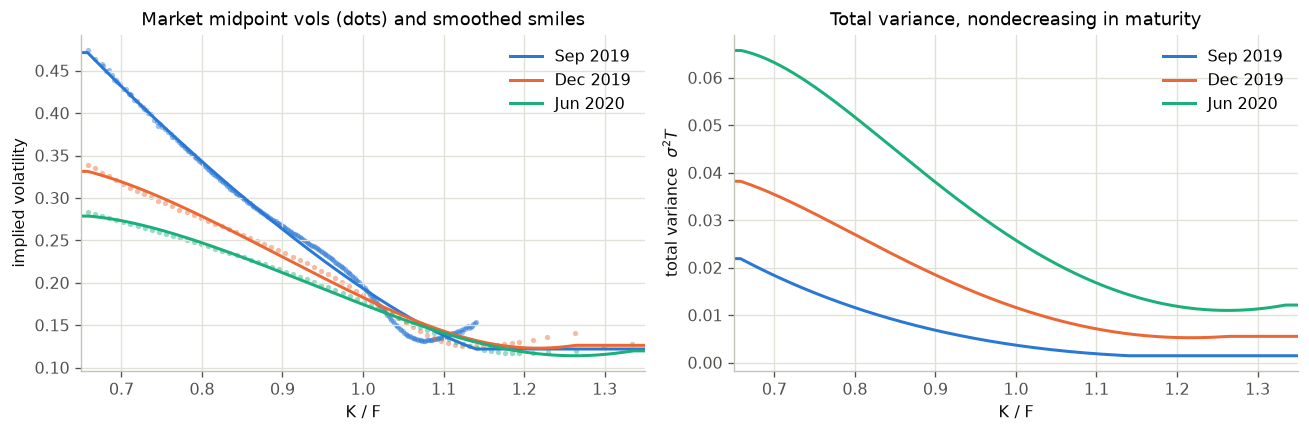

In [2]:
w_fit = bl.smooth_total_variance(smiles)  # shape (3, len(X_GRID)), nondecreasing in maturity
k_grid = np.exp(bl.X_GRID)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for i, smile in enumerate(smiles):
    ax[0].scatter(smile.moneyness, smile.implied_vol, s=10, color=COLORS[i], alpha=0.45, linewidths=0)
    ax[0].plot(k_grid, np.sqrt(w_fit[i] / T[i]), color=COLORS[i], label=labels[i])
    ax[1].plot(k_grid, w_fit[i], color=COLORS[i], label=labels[i])
ax[0].set(xlabel="K / F", ylabel="implied volatility", xlim=(0.65, 1.35),
          title="Market midpoint vols (dots) and smoothed smiles")
ax[1].set(xlabel="K / F", ylabel="total variance  $\\sigma^2 T$", xlim=(0.65, 1.35),
          title="Total variance, nondecreasing in maturity")
ax[0].legend(); ax[1].legend()
fig.tight_layout()

In [3]:
marginals = [bl.marginal_from_total_variance(w, bl.X_GRID) for w in w_fit]
atm_marginals = [bl.lognormal_marginal(row.atm_iv**2 * row["T"]) for _, row in term.iterrows()]


def iv_errors_bp(i, prices):
    # Model minus market Black vol at every kept quote, in basis points of volatility.
    smile, out = smiles[i], []
    for c, k, market in zip(prices, smile.moneyness, smile.implied_vol):
        out.append((bl.implied_vol(c, k, T[i]) - market) * 1e4)
    return np.array(out)


def half_spreads_bp(i):
    smile = smiles[i]
    parity = np.where(smile.type == "put", 1 - smile.moneyness, 0.0)
    vols = []
    for side in ("bid", "ask"):
        side_vols = []
        for c, k in zip(smile[side] / (discounts[i] * forwards[i]) + parity, smile.moneyness):
            try:
                side_vols.append(bl.implied_vol(c, k, T[i]))
            except ValueError:  # bid below intrinsic value
                side_vols.append(np.nan)
        vols.append(np.array(side_vols))
    return (vols[1] - vols[0]) / 2 * 1e4


fit = {}
for i, smile in enumerate(smiles):
    spline = np.sqrt(np.interp(smile.log_moneyness, bl.X_GRID, w_fit[i]) / T[i])
    spline_err = (spline - smile.implied_vol) * 1e4
    marginal_err = iv_errors_bp(i, [marginals[i].call(k) for k in smile.moneyness])
    fit[labels[i]] = {
        "quotes": f"{len(smile)}",
        "smoothed smile, IV RMSE (bp)": f"{np.sqrt(np.mean(spline_err**2)):.1f}",
        "marginal, IV RMSE (bp)": f"{np.sqrt(np.mean(marginal_err**2)):.1f}",
        "marginal, max |IV error| (bp)": f"{np.max(np.abs(marginal_err)):.1f}",
        "median bid-ask half-spread (bp)": f"{np.nanmedian(half_spreads_bp(i)):.1f}",
        "|mean of marginal - 1|": f"{abs(marginals[i].mean() - 1):.1e}",
    }
pd.DataFrame(fit).T

,quotes,"smoothed smile, IV RMSE (bp)","marginal, IV RMSE (bp)","marginal, max |IV error| (bp)",median bid-ask half-spread (bp),|mean of marginal - 1|
Sep 2019,246,96.5,113.3,284.0,16.3,0.0e+00
Dec 2019,65,65.2,65.1,134.0,10.2,0.0e+00
Jun 2020,67,35.9,37.6,104.5,11.4,1.1e-16


The spline is heavily smoothed (smoothing factor $2\times10^{-5}$ per quote in total
variance): the fitted smiles miss the market midpoints by 0.36 to 0.97 vol points (RMSE). The
marginals, after clipping and rescaling to mean one, miss them by 0.38 to 1.13 vol points
(RMSE; up to 2.84 on one Sep 2019 quote), several times the bid-ask half-spread. Everything
below calibrates exactly to these marginals, not to the raw quotes; an arbitrage-free parametric fit (SVI/SSVI) would be the
production choice.

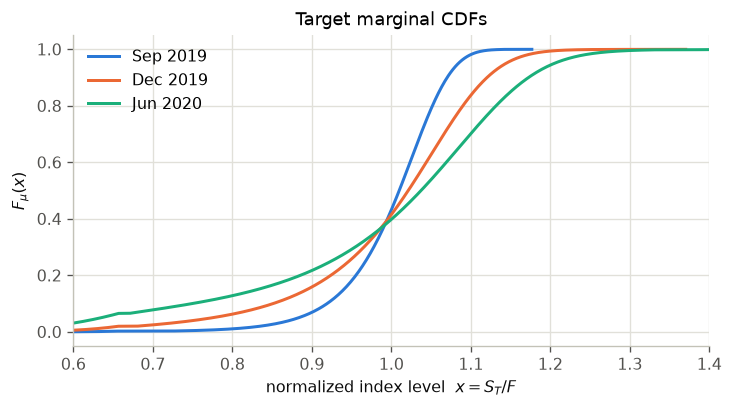

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 3.5))
for i, m in enumerate(marginals):
    ax.plot(m.q, m.u, color=COLORS[i], label=labels[i])
ax.set(xlabel="normalized index level  $x = S_T / F$", ylabel="$F_\\mu(x)$", xlim=(0.6, 1.4),
       title="Target marginal CDFs")
ax.legend()
fig.tight_layout()

## 3. The fixed point $F=\mathcal A F$ (Theorem 2.1)

On $[T_i,T_{i+1}]$ with $\Delta=T_{i+1}-T_i$, the unknown is the CDF $F$ of the latent state
$W_{T_i}$. With the heat kernel $K_t * h(w)=\mathbb E[h(w+\sqrt t Z)]$,

$$\mathcal A F = F_{\mu_i}\circ\Big(K_\Delta * \big(F_{\mu_{i+1}}^{-1}\circ(K_\Delta*F)\big)\Big),
\qquad F=\mathcal A F, \tag{2}$$

and the interval is then given by its terminal map $g=F_{\mu_{i+1}}^{-1}\circ(K_\Delta*F)$:

$$f(t,\cdot)=K_{T_{i+1}-t}*g,\qquad S_t=f(t,W_t). \tag{3}$$

Since $f$ solves the backward heat equation, $S$ is a martingale on the interval, and the fixed
point makes $S_{T_i}\sim\mu_i$ and $S_{T_{i+1}}\sim\mu_{i+1}$. $\mathcal A$ commutes with
translations, so each iterate is recentered to $F(0)=1/2$ (Remark 2.3). The iteration starts
from the linearized solution, Eq. (26). The first interval is the classical one-marginal Bass
construction, $f(T_1,w)=F_{\mu_1}^{-1}(N(w/\sqrt{T_1}))$.

Every convolution $K_t*h$ is computed exactly for the piecewise-linear interpolant of $h$ on
the latent grid, which is also what the Monte Carlo evaluates. The paper suggests
Gauss-Hermite quadrature for these convolutions (Section 3.4.1) and my first implementation used
24 nodes; Section 9 shows why that matters on this smile.

In [5]:
model = bl.calibrate(marginals, T)                         # full smile
model_atm = bl.calibrate(atm_marginals, T)                 # ATM-lognormal comparison
model_gh = bl.calibrate(marginals, T, method="gauss-hermite")  # first implementation


def diagnostics(m):
    rows = {}
    for i, pair in enumerate(m.pairs):
        image = bl.bass_operator(pair.latent_cdf, m.marginals[i], m.marginals[i + 1],
                                 pair.t1 - pair.t0, method=m.method)
        rows[f"{labels[i]} to {labels[i + 1]}"] = {
            "iterations": pair.iterations,
            "last step |F_p+1 - F_p|": f"{pair.errors[-1]:.1e}",
            "residual |AF - F|": f"{np.max(np.abs(image - pair.latent_cdf)):.1e}",
            "Eq. (24) check |F_mu(h) - F|": f"{np.max(np.abs(m.marginals[i].cdf(pair.start) - pair.latent_cdf)):.1e}",
        }
    return pd.DataFrame(rows).T


diagnostics(model)

,iterations,last step |F_p+1 - F_p|,residual |AF - F|,Eq. (24) check |F_mu(h) - F|
Sep 2019 to Dec 2019,10,4.0e-06,1.3e-06,1.6e-05
Dec 2019 to Jun 2020,12,5.6e-06,2.4e-06,1.0e-05


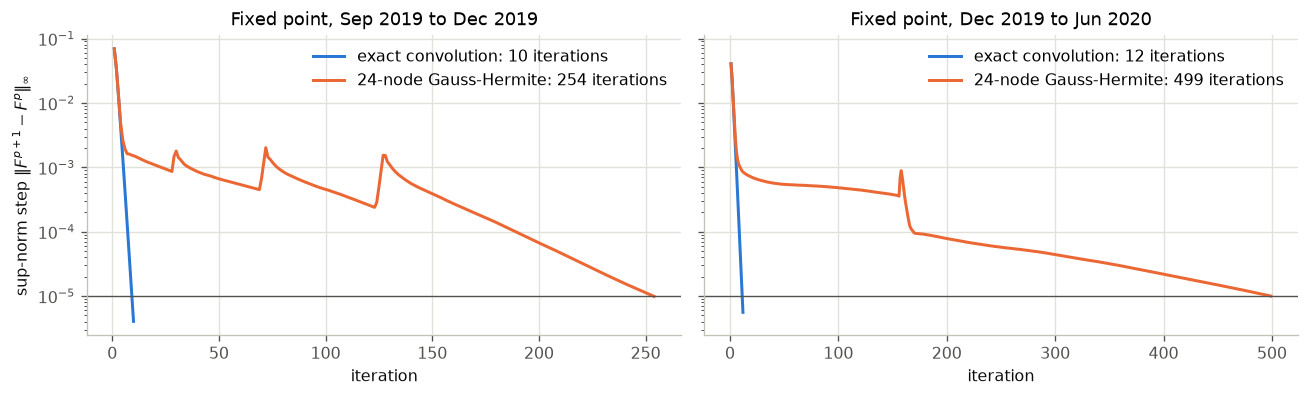

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for i in range(2):
    for m, color, name in ((model, COLORS[0], "exact convolution"),
                           (model_gh, COLORS[1], "24-node Gauss-Hermite")):
        errors = m.pairs[i].errors
        ax[i].semilogy(np.arange(1, len(errors) + 1), errors, color=color,
                       label=f"{name}: {len(errors)} iterations")
    ax[i].axhline(1e-5, color=MUTED, linewidth=0.8)
    ax[i].set(xlabel="iteration", title=f"Fixed point, {labels[i]} to {labels[i + 1]}")
    ax[i].legend()
ax[0].set_ylabel("sup-norm step $\\|F^{p+1}-F^p\\|_\\infty$")
fig.tight_layout()

With exact convolutions the Picard iteration reaches the $10^{-5}$ tolerance in 10 and 12
steps. With the quadrature noise of the 24-node Gauss-Hermite version the same iteration slows down
after the first steps, jumps back several times and needs 254 and 499.

## 4. Exact large-step Monte Carlo

Inside an interval the latent state moves by exact Gaussian increments; at a market date the
asset value is kept and the latent state is reset (Eq. 8),

$$W_{T_i}=f_{[T_i,T_{i+1}]}^{-1}\big(T_i, f_{[T_{i-1},T_i]}(T_i^-,W_{T_i^-})\big),$$

so a path of three market dates needs three Gaussian draws and no time stepping. Each target
call is the quantile integral $\int_0^1 (F_\mu^{-1}(u)-k)^+du$ (Section 4.1, Figure 1).

In [7]:
N_PATHS, SEED = 60_000, 7
X = bl.simulate_market_dates(model, n=N_PATHS, seed=SEED)
X_atm = bl.simulate_market_dates(model_atm, n=N_PATHS, seed=SEED)

repricing = bl.repricing_table(X, marginals, labels=labels)
repricing["|error| / s.e."] = repricing["error"].abs() / repricing["MC s.e."]
print(f"max |error| = {repricing['error'].abs().max():.2e} (normalized units), "
      f"max |error| / s.e. = {repricing['|error| / s.e.'].max():.2f}")
repricing.round({"target call": 5, "MC call": 5, "error": 5, "MC s.e.": 5, "|error| / s.e.": 2})

max |error| = 1.89e-04 (normalized units), max |error| / s.e. = 1.61


,expiry,k,target call,MC call,error,MC s.e.,|error| / s.e.
0,Sep 2019,0.9,0.10384,0.10366,-0.00019,0.00022,0.86
1,Sep 2019,1.0,0.02428,0.02411,-0.00017,0.00012,1.42
2,Sep 2019,1.1,0.00023,0.00021,-0.00001,0.00001,1.61
3,Dec 2019,0.9,0.11624,0.11631,0.00007,0.00033,0.21
4,Dec 2019,1.0,0.04303,0.04300,-0.00003,0.00021,0.13
5,Dec 2019,1.1,0.00575,0.00568,-0.00007,0.00007,0.92
6,Jun 2020,0.9,0.13425,0.13441,0.00016,0.00043,0.38
7,Jun 2020,1.0,0.06398,0.06404,0.00006,0.00030,0.21
8,Jun 2020,1.1,0.01824,0.01826,0.00002,0.00016,0.10


The exotic is an arithmetic Asian call fixed at the three market dates,
$\big(\tfrac13(S_{T_1}+S_{T_2}+S_{T_3})-2847.60\big)^+$, discounted from the last date: a
three-fixing version of the Asian in Section 4.2.3 and Table 2. The full-smile and
ATM-lognormal models share dates, forwards, path count and random numbers, so the paired
difference isolates the effect of the smile.

In [8]:
payoffs = bl.asian_call_payoffs(X, forwards, discounts[-1], spot)
payoffs_atm = bl.asian_call_payoffs(X_atm, forwards, discounts[-1], spot)
difference = payoffs - payoffs_atm


def row(sample):
    se = sample.std(ddof=1) / np.sqrt(len(sample))
    return {"price": sample.mean(), "MC s.e.": se,
            "95% low": sample.mean() - 1.96 * se, "95% high": sample.mean() + 1.96 * se}


asian = pd.DataFrame({"Bass-LV, full smile": row(payoffs),
                      "Bass-LV, ATM-lognormal marginals": row(payoffs_atm),
                      "difference (paired)": row(difference)}).T
asian.round(2)

,price,MC s.e.,95% low,95% high
"Bass-LV, full smile",106.02,0.51,105.02,107.02
"Bass-LV, ATM-lognormal marginals",106.53,0.68,105.20,107.86
difference (paired),-0.51,0.23,-0.97,-0.05


## 5. Local volatility (Section 3.2)

On each interval Itô's formula and the heat equation give

$$\frac{dS_t}{S_t}=\partial_w \log f\big(t,f^{-1}(t,S_t)\big) dB_t,\qquad
\sigma_i(t,S)=\partial_w\log f\big(t,f^{-1}(t,S)\big),$$

evaluated here at the middle of each interval, over the central 99% of each marginal. The
right panel uses the 24-node Gauss-Hermite quadrature of the first implementation.

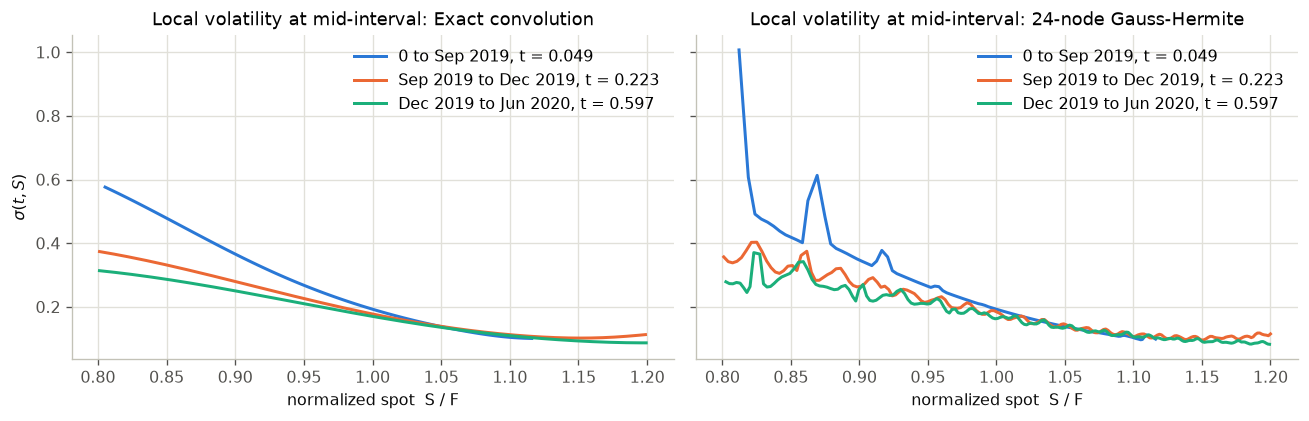

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
names = [f"{a} to {b}" for a, b in zip(["0"] + labels[:-1], labels)]
for panel, m, title in ((0, model, "Exact convolution"), (1, model_gh, "24-node Gauss-Hermite")):
    for i, interval in enumerate(m.intervals):
        t = 0.5 * (interval.t0 + interval.t1)
        S, sigma = interval.local_vol(t)
        lo, hi = m.marginals[i].ppf([0.005, 0.995])  # where the marginal has mass
        keep = (S > max(0.8, lo)) & (S < min(1.2, hi))
        ax[panel].plot(S[keep], sigma[keep], color=COLORS[i], label=f"{names[i]}, t = {t:.3f}")
    ax[panel].set(xlabel="normalized spot  S / F", title=f"Local volatility at mid-interval: {title}")
    ax[panel].legend()
ax[0].set(ylabel="$\\sigma(t, S)$")
fig.tight_layout()

## 6. Forward-start options (Section 4.2.1)

The paper compares $\mathbb E[(S_{T_{i+1}}/S_{T_i}-K)^+]$ under Bass-LV and Dupire local
volatility (Figure 2). A Dupire implementation is out of scope here; the figure shows the
Bass-LV forward-start prices and the Black volatilities they imply, with the ratio normalized by
its simulated mean.

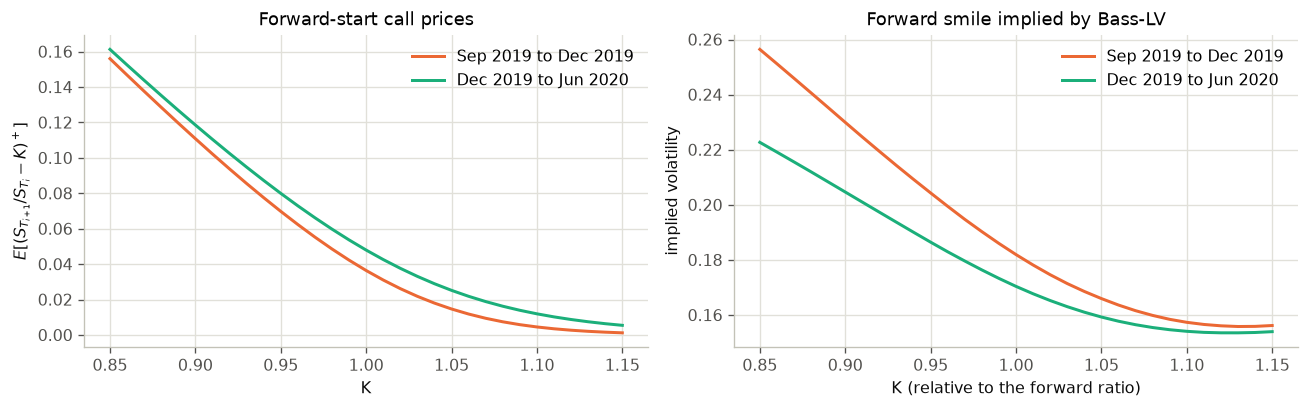

In [10]:
ks = np.linspace(0.85, 1.15, 31)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i in range(2):
    prices = bl.forward_start_calls(X, forwards, i, ks)
    ratio = X[:, i + 1] / X[:, i] * forwards[i + 1] / forwards[i]
    rho, dt = ratio.mean(), T[i + 1] - T[i]
    vols = [bl.implied_vol(np.maximum(ratio / rho - k, 0).mean(), k, dt) for k in ks]
    name = f"{labels[i]} to {labels[i + 1]}"
    ax[0].plot(ks, prices, color=COLORS[i + 1], label=name)
    ax[1].plot(ks, vols, color=COLORS[i + 1], label=name)
ax[0].set(xlabel="K", ylabel="$E[(S_{T_{i+1}}/S_{T_i}-K)^+]$", title="Forward-start call prices")
ax[1].set(xlabel="K (relative to the forward ratio)", ylabel="implied volatility",
          title="Forward smile implied by Bass-LV")
ax[0].legend(); ax[1].legend()
fig.tight_layout()

## 7. Vega Greeks and the vanilla hedge (Section 5)

Section 5.1 in three steps:

1. bump each terminal map with triangular hats, $f_i\to f_i+\varepsilon h_i^l$ (Eq. 9), three
   per expiry, with knots at quantiles of $W_{T_i^-}$ spanning its central 90%;
2. differentiate the Asian price pathwise: a backward sweep carries $\partial \text{payoff}/\partial S_{T_i}$
   through the resets (Eq. 10), and the market-date term of Eq. (11) gives the hat
   sensitivity (the within-interval sum is empty because the Asian fixes only at market dates);
3. propagate the bumps to the marginal CDFs by forward induction (Eqs. 12-15), integrate to
   call sensitivities, and solve for the vanilla portfolio whose hat sensitivities cancel the
   Asian's: nine calls (strikes 0.9, 1.0, 1.1 at each expiry) against nine hats.

In [11]:
N_GREEK_PATHS, GREEK_SEED = 30_000, 19
triangles = bl.hat_triangles(model, per_expiry=3)
bumps = [(j, t) for j in range(3) for t in triangles[j]]
instruments = [(i, k) for i in range(3) for k in (0.9, 1.0, 1.1)]

Xg, W_start, W_end = bl.simulate_latents(model, n=N_GREEK_PATHS, seed=GREEK_SEED)
adjoint = bl.pathwise_adjoint(model, bl.asian_payoff_gradient(Xg, forwards, discounts[-1], spot),
                              W_start, W_end, forwards)
exotic, exotic_se = np.array([bl.exotic_hat_sensitivity(model, j, t, adjoint, W_start, W_end,
                                                        forwards, with_se=True) for j, t in bumps]).T
vanilla = bl.vanilla_sensitivities(model, bumps, instruments, forwards, discounts)
hedge = bl.solve_vega_hedge(vanilla, exotic)

print(f"Asian hat sensitivities: MC s.e. {exotic_se.min():.1f} to {exotic_se.max():.1f} "
      f"(values {exotic.min():.1f} to {exotic.max():.1f}, index points per unit bump)")
print(f"vanilla sensitivity matrix: rank {hedge.rank}/9, condition number {hedge.condition_number:.2e}")
print(f"largest hat sensitivity left after hedging: {np.max(np.abs(hedge.residual)):.1e}")

Asian hat sensitivities: MC s.e. 0.9 to 4.2 (values -73.8 to 207.5, index points per unit bump)
vanilla sensitivity matrix: rank 9/9, condition number 1.41e+04
largest hat sensitivity left after hedging: 1.6e-11


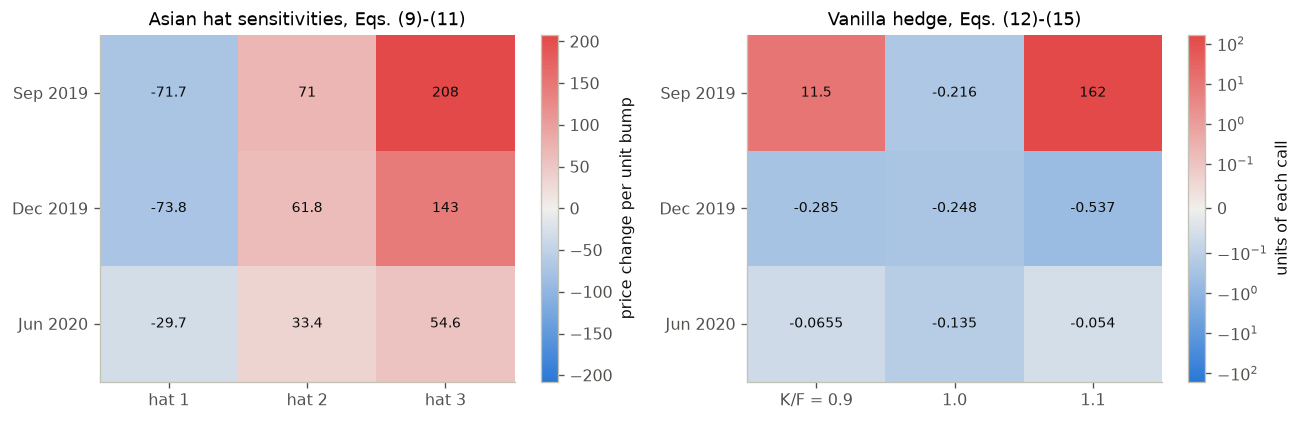

In [12]:
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
grid_e, grid_w = exotic.reshape(3, 3), hedge.weights.reshape(3, 3)
scale = np.max(np.abs(grid_e))
image = ax[0].imshow(grid_e, cmap=diverging, vmin=-scale, vmax=scale, aspect="auto")
fig.colorbar(image, ax=ax[0], label="price change per unit bump")
ax[0].set(xticks=range(3), xticklabels=["hat 1", "hat 2", "hat 3"], title="Asian hat sensitivities, Eqs. (9)-(11)")
scale = np.max(np.abs(grid_w))
image = ax[1].imshow(grid_w, cmap=diverging, norm=SymLogNorm(linthresh=0.1, vmin=-scale, vmax=scale), aspect="auto")
fig.colorbar(image, ax=ax[1], label="units of each call")
ax[1].set(xticks=range(3), xticklabels=["K/F = 0.9", "1.0", "1.1"], title="Vanilla hedge, Eqs. (12)-(15)")
for a, values in ((ax[0], grid_e), (ax[1], grid_w)):
    a.set(yticks=range(3), yticklabels=labels)
    a.grid(False)
    for r in range(3):
        for c in range(3):
            a.text(c, r, f"{values[r, c]:.3g}", ha="center", va="center", fontsize=8.5, color=INK)
fig.tight_layout()

Nine calls against nine bumps make the hedge an exactly determined linear system, so the
residual only measures the linear solve. The weights are not robust: the system is
ill-conditioned and the short-dated wing calls take large positions.

**Check against bump-and-revalue.** Each terminal map is bumped by $\pm10^{-3}$ hats and the
Asian and the nine calls are repriced by Monte Carlo with common random numbers. The pathwise
Asian sensitivities and the semi-analytic call sensitivities are compared with these finite
differences.

In [13]:
def bump_and_revalue(m, n=200_000, seed=5, eps=1e-3):
    X_b, W_s, W_e = bl.simulate_latents(m, n=n, seed=seed)
    adj = bl.pathwise_adjoint(m, bl.asian_payoff_gradient(X_b, forwards, discounts[-1], spot), W_s, W_e, forwards)
    tri = bl.hat_triangles(m, per_expiry=3)
    bumps_m = [(j, t) for j in range(3) for t in tri[j]]
    pathwise = np.array([bl.exotic_hat_sensitivity(m, j, t, adj, W_s, W_e, forwards) for j, t in bumps_m])
    semi = bl.vanilla_sensitivities(m, bumps_m, instruments, forwards, discounts)

    def prices(bumped):
        paths = bl.simulate_latents(bumped, n=n, seed=seed)[0]
        calls = [discounts[i] * forwards[i] * np.maximum(paths[:, i] - k, 0).mean() for i, k in instruments]
        return bl.asian_call(paths, forwards, discounts[-1], spot)[0], np.array(calls)

    fd_asian, fd_calls = [], []
    for j, t in bumps_m:
        (a_up, c_up), (a_dn, c_dn) = prices(bl.bump_terminal_map(m, j, t, eps)), prices(bl.bump_terminal_map(m, j, t, -eps))
        fd_asian.append((a_up - a_dn) / (2 * eps))
        fd_calls.append((c_up - c_dn) / (2 * eps))
    fd_asian, fd_calls = np.array(fd_asian), np.array(fd_calls).T
    return {"Asian, Eqs. (10)-(11)": np.max(np.abs(pathwise - fd_asian)) / np.max(np.abs(fd_asian)),
            "calls, Eqs. (12)-(15)": np.max(np.abs(semi - fd_calls)) / np.max(np.abs(fd_calls))}


check = pd.Series(bump_and_revalue(model), name="max |analytic - bump| / max |bump|")
check.map(lambda v: f"{v:.1%}").to_frame()

,max |analytic - bump| / max |bump|
"Asian, Eqs. (10)-(11)",0.2%
"calls, Eqs. (12)-(15)",1.3%


## 8. Bass2: a general reference kernel (Section 6)

Replacing the Brownian increment by an independent diffusion $X$ (Eq. 16) only changes the two
kernels of the fixed point (Theorem 6.1):

$$\mathcal A^X F=F_{\mu_1}\circ\Big(K^{-X}*\big(F_{\mu_2}^{-1}\circ(K^X*F)\big)\Big),\qquad F=\mathcal A^XF. \tag{17}$$

`bl.bass2_operator` takes the two kernels as functions. With Brownian kernels it must reproduce
Eq. (2), so the calibrated $F$ is a fixed point:

In [14]:
for i, pair in enumerate(model.pairs):
    K_X, K_minus_X = bl.brownian_kernels(pair.t1 - pair.t0)
    image = bl.recenter(bl.bass2_operator(pair.latent_cdf, marginals[i], marginals[i + 1], K_X, K_minus_X))
    print(f"{labels[i]} to {labels[i + 1]}: Brownian-kernel Eq. (17) residual {np.max(np.abs(image - pair.latent_cdf)):.1e}")

Sep 2019 to Dec 2019: Brownian-kernel Eq. (17) residual 1.3e-06
Dec 2019 to Jun 2020: Brownian-kernel Eq. (17) residual 2.4e-06


The two Section 6 applications need inputs this snapshot does not contain. Future skew
(Section 6.2) calibrates the kernel of $X$ to a forward-starting smile through Eq. (18), and the
paper notes that convergence of that loop is not obvious. The stochastic-volatility kernel
(Section 6.3, Eqs. 19-22) needs a law for the volatility factor, for which the paper gives no
numerical example. Both are left out rather than fed with invented inputs.

## 9. Numerical note: exact convolution versus Gauss-Hermite quadrature

The paper suggests Gauss-Hermite quadrature for the heat-kernel convolutions (Section 3.4.1),
and the first implementation computed every $K_t*h$ with 24 nodes. That is accurate for smooth
$h$, but the terminal maps built from this smile are kinked: the Breeden-Litzenberger CDF is
clipped where the smoothed smile has negative butterflies (an artefact of the spline fit, which
an arbitrage-free SVI/SSVI fit would reduce), and the quantile function is flat beyond the
probability grid. The quadrature error in the start map
$h=K_\Delta*g$ then reaches about $10^{-2}$ of the forward. The marginals are still matched,
since the fixed point uses the same $h$, but $\mathbb E[S_{T_{i+1}}\mid S_{T_i}]\neq S_{T_i}$:
the simulated model is no longer a martingale. Binning paths by deciles of $S_{T_i}$ shows it:

Sep 2019 to Dec 2019: Gauss-Hermite start map minus exact convolution of the same terminal map, max 1.4e-02 (forward-normalized)
Dec 2019 to Jun 2020: Gauss-Hermite start map minus exact convolution of the same terminal map, max 1.7e-02 (forward-normalized)


exact convolution: largest conditional drift 0.08% of the forward, max |z| = 1.8
24-node Gauss-Hermite: largest conditional drift 1.22% of the forward, max |z| = 17.8


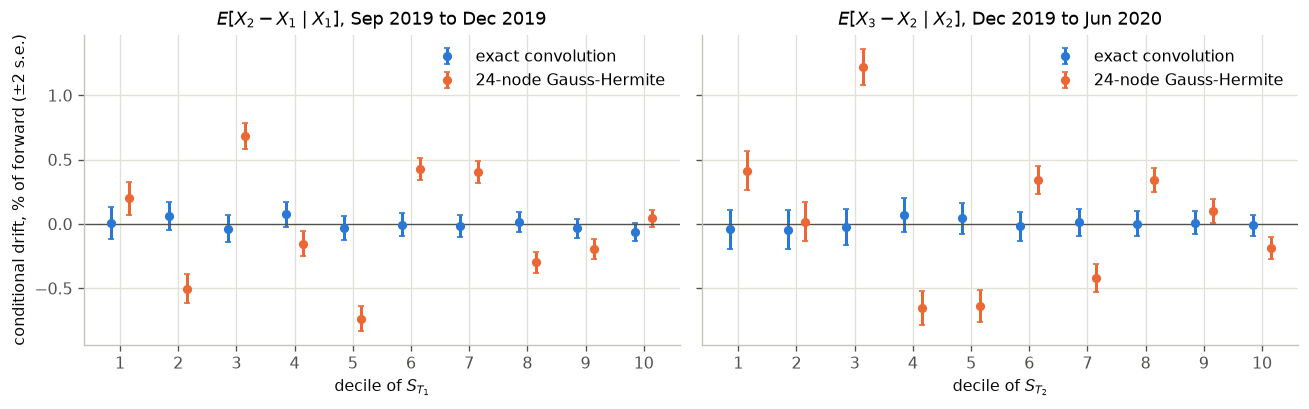

In [15]:
for i, pair in enumerate(model_gh.pairs):
    exact_h = np.maximum.accumulate(bl.heat(pair.terminal, bl.W_GRID, pair.t1 - pair.t0))
    live = (pair.latent_cdf > 1e-3) & (pair.latent_cdf < 1 - 1e-3)  # central 99.8% of W_{T_i}
    print(f"{labels[i]} to {labels[i + 1]}: Gauss-Hermite start map minus exact convolution of the "
          f"same terminal map, max {np.max(np.abs(pair.start - exact_h)[live]):.1e} (forward-normalized)")

model_atm_gh = bl.calibrate(atm_marginals, T, method="gauss-hermite")
drift = {name: bl.martingale_diagnostic(bl.simulate_market_dates(m, n=400_000, seed=3))
         for name, m in (("exact convolution", model), ("24-node Gauss-Hermite", model_gh))}
for name, table in drift.items():
    print(f"{name}: largest conditional drift {100 * table['mean increment'].abs().max():.2f}% "
          f"of the forward, max |z| = {table['z'].abs().max():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for i in range(2):
    for offset, (name, table), color in zip((-0.15, 0.15), drift.items(), COLORS[:2]):
        rows = table[table.interval == i + 1]
        ax[i].errorbar(rows["bin"] + offset, 100 * rows["mean increment"], yerr=200 * rows["s.e."],
                       fmt="o", markersize=4.5, color=color, capsize=2, label=name)
    ax[i].axhline(0, color=MUTED, linewidth=0.8)
    ax[i].set(xlabel=f"decile of $S_{{T_{i + 1}}}$", xticks=range(1, 11),
              title=f"$E[X_{{{i + 2}}} - X_{{{i + 1}}} \\mid X_{{{i + 1}}}]$, {labels[i]} to {labels[i + 1]}")
    ax[i].legend()
ax[0].set_ylabel("conditional drift, % of forward (±2 s.e.)")
fig.tight_layout()

In [16]:
def headline(m, m_atm):
    paths = bl.simulate_market_dates(m, n=N_PATHS, seed=SEED)
    paths_atm = bl.simulate_market_dates(m_atm, n=N_PATHS, seed=SEED)
    table = bl.repricing_table(paths, m.marginals)
    full = bl.asian_call(paths, forwards, discounts[-1], spot)
    atm = bl.asian_call(paths_atm, forwards, discounts[-1], spot)
    diff = (bl.asian_call_payoffs(paths, forwards, discounts[-1], spot)
            - bl.asian_call_payoffs(paths_atm, forwards, discounts[-1], spot))
    tri = bl.hat_triangles(m, per_expiry=3)
    bumps_m = [(j, t) for j in range(3) for t in tri[j]]
    X_g, W_s, W_e = bl.simulate_latents(m, n=N_GREEK_PATHS, seed=GREEK_SEED)
    adj = bl.pathwise_adjoint(m, bl.asian_payoff_gradient(X_g, forwards, discounts[-1], spot), W_s, W_e, forwards)
    ex = np.array([bl.exotic_hat_sensitivity(m, j, t, adj, W_s, W_e, forwards) for j, t in bumps_m])
    h = bl.solve_vega_hedge(bl.vanilla_sensitivities(m, bumps_m, instruments, forwards, discounts), ex)
    K_X, K_minus_X = bl.brownian_kernels(m.pairs[0].t1 - m.pairs[0].t0, method=m.method)
    b2 = bl.recenter(bl.bass2_operator(m.pairs[0].latent_cdf, m.marginals[0], m.marginals[1], K_X, K_minus_X))
    z = bl.martingale_diagnostic(bl.simulate_market_dates(m, n=400_000, seed=3))["z"].abs().max()
    bump = bump_and_revalue(m)
    return {
        "fixed-point iterations": " and ".join(str(p.iterations) for p in m.pairs),
        "repricing, max |error| (9 calls)": f"{table.error.abs().max():.2e}",
        "repricing, max |error| / s.e.": f"{(table.error.abs() / table['MC s.e.']).max():.2f}",
        "Asian, full smile": f"{full[0]:.2f} ± {full[1]:.2f}",
        "Asian, ATM-lognormal": f"{atm[0]:.2f} ± {atm[1]:.2f}",
        "Asian, paired difference": f"{diff.mean():.2f} ± {diff.std(ddof=1) / np.sqrt(len(diff)):.2f}",
        "martingale check, max |z| (20 bins, 400k paths)": f"{z:.1f}",
        "vanilla matrix rank, condition number": f"{h.rank}, {h.condition_number:.2e}",
        "residual after hedging": f"{np.max(np.abs(h.residual)):.1e}",
        "Asian Greeks vs bump-and-revalue": f"{bump['Asian, Eqs. (10)-(11)']:.1%}",
        "call Greeks vs bump-and-revalue": f"{bump['calls, Eqs. (12)-(15)']:.1%}",
        "Bass2 Brownian-kernel residual": f"{np.max(np.abs(b2 - m.pairs[0].latent_cdf)):.1e}",
    }


comparison = pd.DataFrame({"exact convolution (default)": headline(model, model_atm),
                           "24-node Gauss-Hermite (first implementation)": headline(model_gh, model_atm_gh)})
comparison

,exact convolution (default),24-node Gauss-Hermite (first implementation)
fixed-point iterations,10 and 12,254 and 499
"repricing, max |error| (9 calls)",1.89e-04,2.53e-04
"repricing, max |error| / s.e.",1.61,1.61
"Asian, full smile",106.02 ± 0.51,105.86 ± 0.51
"Asian, ATM-lognormal",106.53 ± 0.68,106.53 ± 0.68
"Asian, paired difference",-0.51 ± 0.23,-0.66 ± 0.24
"martingale check, max |z| (20 bins, 400k paths)",1.8,17.8
"vanilla matrix rank, condition number","9, 1.41e+04","9, 1.30e+04"
residual after hedging,1.6e-11,3.9e-11
Asian Greeks vs bump-and-revalue,0.2%,0.8%


The Gauss-Hermite column is computed with `method="gauss-hermite"`. Its vega-matrix and hedge
figures include one later fix: the strike integral of the call sensitivities now starts at the
strike itself instead of the next grid node. With the quadrature the call Greeks also disagree with bump-and-revalue on the simulated model: the
forward induction of Eqs. (12)-(15) follows the quadrature, the Monte Carlo does not.

**Scope.** This is a faithful replication on one end-of-day snapshot with three expiries, not
a production calibrator: the smile fit is a smoothing spline rather than an arbitrage-free
parametrization, the Monte Carlo errors are quoted at fixed seeds, and the Section 6
extensions stop at the operator, checked with Brownian kernels only.